In [ ]:
!wget -r -N -c -np https://physionet.org/files/mitdb/1.0.0/

--2026-01-04 11:26:38--  https://physionet.org/files/mitdb/1.0.0/
Resolving physionet.org (physionet.org)... 18.18.42.54
Connecting to physionet.org (physionet.org)|18.18.42.54|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [text/html]
Saving to: ‘physionet.org/files/mitdb/1.0.0/index.html’

physionet.org/files     [ <=>                ]  22.87K  --.-KB/s    in 0.01s   

Last-modified header missing -- time-stamps turned off.
2026-01-04 11:26:39 (1.95 MB/s) - ‘physionet.org/files/mitdb/1.0.0/index.html’ saved [23416]

Loading robots.txt; please ignore errors.
--2026-01-04 11:26:39--  https://physionet.org/robots.txt
Reusing existing connection to physionet.org:443.
HTTP request sent, awaiting response... 200 OK

    The file is already fully retrieved; nothing to do.

--2026-01-04 11:26:39--  https://physionet.org/files/mitdb/1.0.0/mitdbdir/
Reusing existing connection to physionet.org:443.
HTTP request sent, awaiting response... 304 Not Modified


In [ ]:
!pip install wfdb pyarrow

In [ ]:
import wfdb
import pandas as pd
import numpy as np
import os

# Rutas
input_dir = '/content/physionet.org/files/mitdb/1.0.0/'
output_file = '/content/mitdb_all_records.parquet' # Un solo archivo para todo

# Detectar registros (IDs 100, 101, etc.)
files = [f for f in os.listdir(input_dir) if f.endswith('.hea')]
record_ids = sorted(list(set([f.split('.')[0] for f in files])))

print(f"Encontrados {len(record_ids)} registros. Unificando en un solo dataset...")

all_dataframes = [] # Lista para guardar temporalmente cada paciente

for rec_id in record_ids:
    try:
        path_to_record = os.path.join(input_dir, rec_id)

        # Leemos con WFDB
        record = wfdb.rdrecord(path_to_record)
        annotation = wfdb.rdann(path_to_record, 'atr')

        # Pasamos a DataFrame
        df = pd.DataFrame(record.p_signal, columns=record.sig_name)

        # --- AÑADIMOS EL ID DEL PACIENTE ---
        # Esto es vital para distinguir datos en un archivo único
        df['record_id'] = rec_id
        df['fs'] = record.fs

        # Agregamos anotaciones (Lógica idéntica a la anterior)
        df['annotation'] = None
        valid_indices = annotation.sample < len(df)

        # Usamos índices seguros
        safe_samples = annotation.sample[valid_indices]
        safe_symbols = np.array(annotation.symbol)[valid_indices]

        df.loc[safe_samples, 'annotation'] = safe_symbols

        # Optimizamos tipos de datos para ahorrar memoria RAM (Opcional pero recomendado)
        df['record_id'] = df['record_id'].astype('category')

        # Añadimos a la lista
        all_dataframes.append(df)
        print(f"Procesado: {rec_id}")

    except Exception as e:
        print(f"Error en {rec_id}: {e}")

# --- UNIÓN FINAL ---
print("Concatenando todos los pacientes (esto puede tardar un poco)...")
full_df = pd.concat(all_dataframes, ignore_index=True)

print("Guardando archivo Parquet gigante...")
full_df.to_parquet(output_file, engine='pyarrow', compression='snappy')

print(f"¡Listo! Dataset único guardado en: {output_file}")

Encontrados 48 registros. Unificando en un solo dataset...
Procesado: 100
Procesado: 101
Procesado: 102
Procesado: 103
Procesado: 104
Procesado: 105
Procesado: 106
Procesado: 107
Procesado: 108
Procesado: 109
Procesado: 111
Procesado: 112
Procesado: 113
Procesado: 114
Procesado: 115
Procesado: 116
Procesado: 117
Procesado: 118
Procesado: 119
Procesado: 121
Procesado: 122
Procesado: 123
Procesado: 124
Procesado: 200
Procesado: 201
Procesado: 202
Procesado: 203
Procesado: 205
Procesado: 207
Procesado: 208
Procesado: 209
Procesado: 210
Procesado: 212
Procesado: 213
Procesado: 214
Procesado: 215
Procesado: 217
Procesado: 219
Procesado: 220
Procesado: 221
Procesado: 222
Procesado: 223
Procesado: 228
Procesado: 230
Procesado: 231
Procesado: 232
Procesado: 233
Procesado: 234
Concatenando todos los pacientes (esto puede tardar un poco)...
Guardando archivo Parquet gigante...
¡Listo! Dataset único guardado en: /content/mitdb_all_records.parquet


Columnas disponibles: Index(['MLII', 'V5', 'record_id', 'fs', 'annotation', 'V1', 'V2', 'V4'], dtype='object')
Total de muestras en el dataset: 31200000
Muestras del paciente 100: 650000


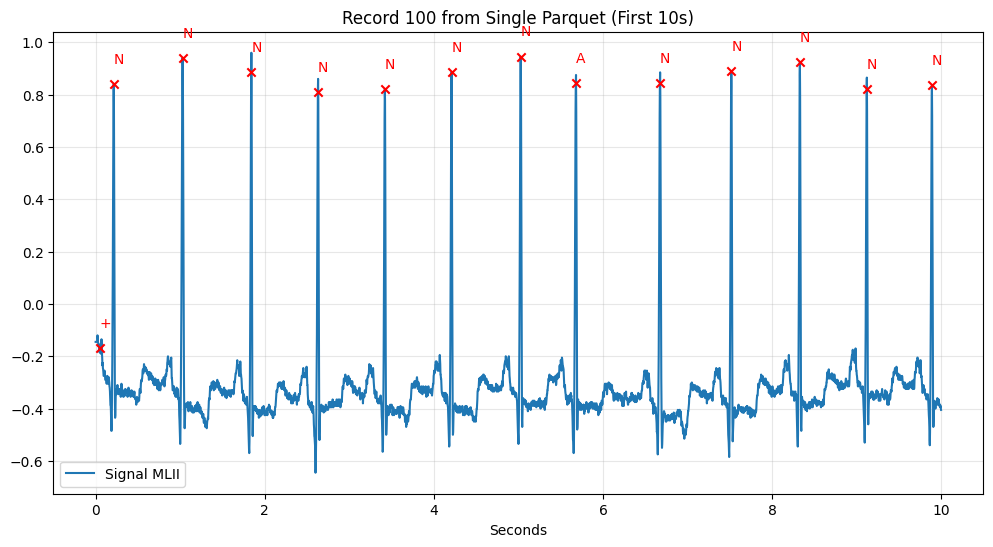

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Cargar el dataset COMPLETO
parquet_file = '/content/mitdb_all_records.parquet'
df_completo = pd.read_parquet(parquet_file)

print("Columnas disponibles:", df_completo.columns)
print(f"Total de muestras en el dataset: {len(df_completo)}")

# 2. FILTRAR: Seleccionamos solo al paciente '100' para trabajar
target_id = '100'
# Aquí usamos la columna nueva 'record_id' que creamos antes
df_patient = df_completo[df_completo['record_id'] == target_id].copy()

# Reiniciamos el índice para que empiece en 0 (tiempo 0)
df_patient.reset_index(drop=True, inplace=True)

print(f"Muestras del paciente {target_id}: {len(df_patient)}")

# 3. GRAFICAR (Igual que antes, pero usando df_patient)
fs = 360
samples_to_plot = 10 * fs
segment = df_patient.iloc[:samples_to_plot]

plt.figure(figsize=(12, 6))

# Graficar señal (asumiendo que MLII es la primera columna de señal)
# Nota: La columna 0 es 'record_id' o la señal, mejor buscamos por nombre si es posible,
# o asumimos que las señales son las primeras columnas numéricas.
signal_col = 'MLII' if 'MLII' in segment.columns else segment.columns[0]

plt.plot(segment.index / fs, segment[signal_col], label=f'Signal {signal_col}')

# Pintar anotaciones
annotations = segment.dropna(subset=['annotation'])
plt.scatter(annotations.index / fs, annotations[signal_col], c='red', marker='x', zorder=5)

for idx, row in annotations.iterrows():
    plt.annotate(row['annotation'], (idx/fs, row[signal_col]), xytext=(0, 15), textcoords='offset points', color='red')

plt.title(f'Record {target_id} from Single Parquet (First 10s)')
plt.xlabel('Seconds')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Signal data type: <class 'numpy.ndarray'>
Signal shape: (650000, 2)


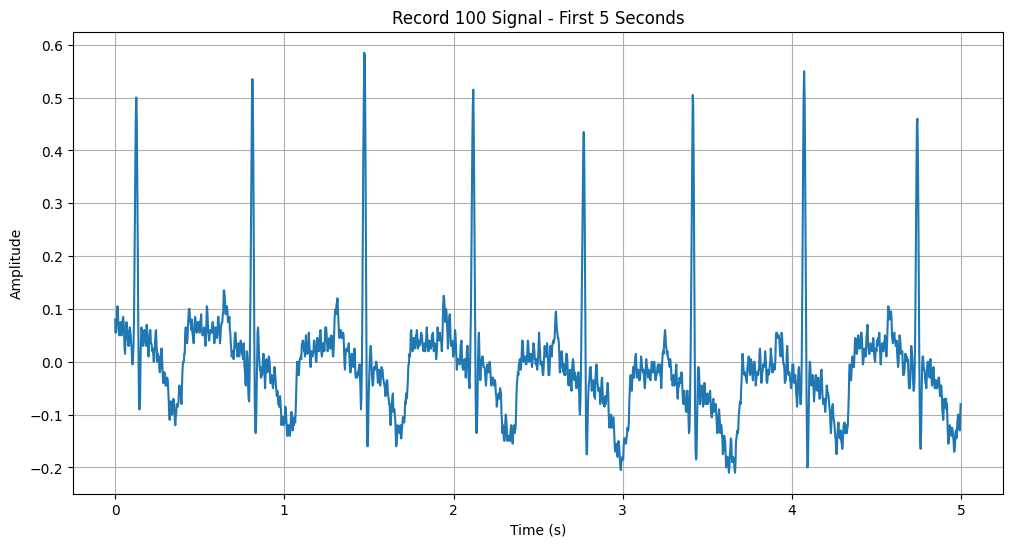

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Access the physical signals from the record object
signal_array = record.p_signal # Corrected from record.p_signals to record.p_signal

print(f"Signal data type: {type(signal_array)}")
print(f"Signal shape: {signal_array.shape}")

# Plot the first 5 seconds of the signal
# Assuming the sampling frequency (fs) is available in record.fs

fs = record.fs
five_seconds_samples = 5 * fs

plt.figure(figsize=(12, 6))
plt.plot(np.arange(five_seconds_samples) / fs, signal_array[2000:2000+int(five_seconds_samples), 1]) # Plotting only the first lead
plt.title('Record 100 Signal - First 5 Seconds')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

In [ ]:
print("Annotation object attributes:")
#display(annotation.__dict__)

print("\nFirst 10 annotation samples and symbols:")
for i in range(min(100, len(annotation.sample))):
    print(f"Sample: {annotation.sample[i]}, Symbol: {annotation.symbol[i]}")

Annotation object attributes:

First 10 annotation samples and symbols:
Sample: 52, Symbol: +
Sample: 135, Symbol: N
Sample: 366, Symbol: N
Sample: 606, Symbol: N
Sample: 841, Symbol: N
Sample: 1082, Symbol: N
Sample: 1327, Symbol: N
Sample: 1562, Symbol: N
Sample: 1794, Symbol: N
Sample: 2042, Symbol: N
Sample: 2289, Symbol: N
Sample: 2528, Symbol: N
Sample: 2759, Symbol: N
Sample: 2994, Symbol: N
Sample: 3227, Symbol: N
Sample: 3463, Symbol: N
Sample: 3704, Symbol: N
Sample: 3938, Symbol: N
Sample: 4166, Symbol: N
Sample: 4400, Symbol: N
Sample: 4646, Symbol: N
Sample: 4880, Symbol: N
Sample: 5108, Symbol: N
Sample: 5339, Symbol: N
Sample: 5572, Symbol: N
Sample: 5805, Symbol: N
Sample: 6036, Symbol: N
Sample: 6271, Symbol: N
Sample: 6506, Symbol: N
Sample: 6736, Symbol: N
Sample: 6974, Symbol: N
Sample: 7210, Symbol: N
Sample: 7445, Symbol: N
Sample: 7676, Symbol: N
Sample: 7909, Symbol: N
Sample: 8142, Symbol: N
Sample: 8380, Symbol: N
Sample: 8622, Symbol: N
Sample: 8852, Symbol: 

In [ ]:
import pandas as pd
import os

# --- Save Signal Data to Parquet ---

# Get sampling frequency from the record
fs = record.fs

# Create a time index for the signal data
time = np.arange(signal_array.shape[0]) / fs

# Create a DataFrame for the signal data
df_signal = pd.DataFrame(signal_array, columns=[f'Lead_{i+1}' for i in range(signal_array.shape[1])])
df_signal['Time_Seconds'] = time

# Define the output file path for signals
signals_parquet_path = 'mitbih_record_100_signals.parquet'
df_signal.to_parquet(signals_parquet_path, index=False)

print(f"Signal data saved to: {signals_parquet_path}")

Signal data saved to: mitbih_record_100_signals.parquet


In [ ]:

# --- Save Annotation Data to Parquet ---

# Create a DataFrame for the annotation data
df_annotation = pd.DataFrame({
    'Sample': annotation.sample,
    'Symbol': annotation.symbol,
    'Aux_Notes': annotation.aux_note # Include auxiliary notes if available
})

# Define the output file path for annotations
annotations_parquet_path = 'mitbih_record_100_annotations.parquet'
df_annotation.to_parquet(annotations_parquet_path, index=False)

print(f"Annotation data saved to: {annotations_parquet_path}")

# Display the first few rows of the saved DataFrames for verification
print("\nFirst 5 rows of Signal DataFrame:")
display(df_signal.head())

print("\nFirst 5 rows of Annotation DataFrame:")
display(df_annotation.head())

Annotation data saved to: mitbih_record_100_annotations.parquet

First 5 rows of Signal DataFrame:


,Lead_1,Lead_2,Time_Seconds
0,-0.08,0.135,0.000000
1,-0.08,0.135,0.002778
2,-0.08,0.135,0.005556
3,-0.08,0.135,0.008333
4,-0.08,0.135,0.011111



First 5 rows of Annotation DataFrame:


,Sample,Symbol,Aux_Notes
0,52,+,(N 
1,135,N,
2,366,N,
3,606,N,
4,841,N,


In [ ]:
df_signal.head()

,Lead_1,Lead_2,Time_Seconds
0,-0.08,0.135,0.000000
1,-0.08,0.135,0.002778
2,-0.08,0.135,0.005556
3,-0.08,0.135,0.008333
4,-0.08,0.135,0.011111


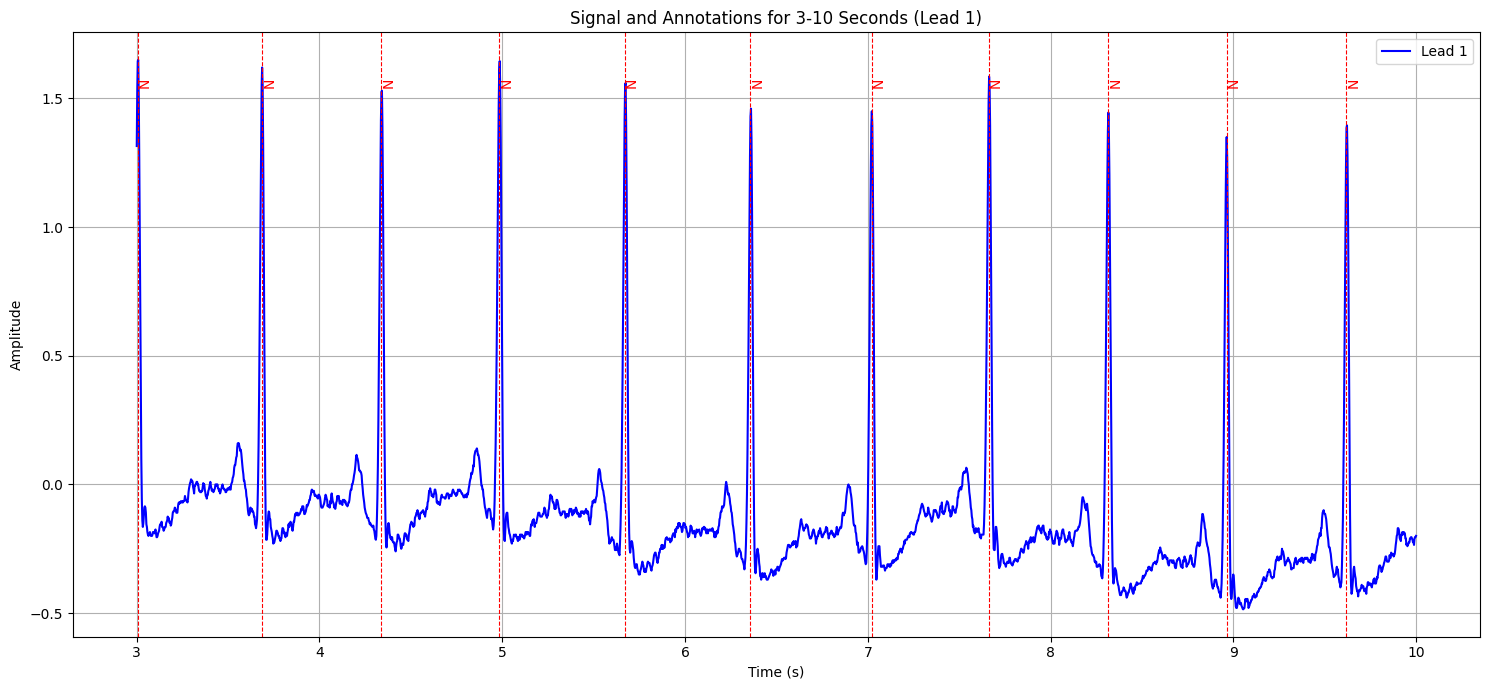

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define the 5-second segment to plot
start_time = 3  # seconds
end_time = 10    # seconds

# Filter df_signal for the chosen time range
df_signal_segment = df_signal[(df_signal['Time_Seconds'] >= start_time) & (df_signal['Time_Seconds'] <= end_time)]

# Get sampling frequency (already available as `fs` from previous steps)
# fs = record.fs # uncomment if fs is not in scope

# Filter df_annotation for the chosen time range (converting time to samples)
start_sample = int(start_time * fs)
end_sample = int(end_time * fs)
df_annotation_segment = df_annotation[(df_annotation['Sample'] >= start_sample) & (df_annotation['Sample'] <= end_sample)]

# Plotting
plt.figure(figsize=(15, 7))

# Plot Lead 1 of the signal
plt.plot(df_signal_segment['Time_Seconds'], df_signal_segment['Lead_1'], label='Lead 1', color='blue')

# Add annotations to the plot
for _, row in df_annotation_segment.iterrows():
    annotation_time = row['Sample'] / fs
    annotation_symbol = row['Symbol']
    plt.axvline(x=annotation_time, color='red', linestyle='--', linewidth=0.8, label=f'Annotation: {annotation_symbol}' if _ == 0 else "") # Add label only once
    plt.text(annotation_time, plt.gca().get_ylim()[1] * 0.9, annotation_symbol, color='red', rotation=90, verticalalignment='top')

plt.title(f'Signal and Annotations for {start_time}-{end_time} Seconds (Lead 1)')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Filter annotations to find non-normal beats (anomalies)
anomalies_df = df_annotation[(df_annotation['Symbol'] != 'N') & (df_annotation['Symbol'] != '+')]

if not anomalies_df.empty:
    # Get the first anomaly
    first_anomaly = anomalies_df.iloc[0]
    first_anomaly_sample = first_anomaly['Sample']

    # Convert sample to time in seconds
    # The sampling frequency (fs) was defined earlier when loading the record
    first_anomaly_time_seconds = first_anomaly_sample / fs

    print(f"The first anomaly is '{first_anomaly['Symbol']}' at sample {first_anomaly_sample}, which corresponds to {first_anomaly_time_seconds:.2f} seconds.")
else:
    print("No anomalies (non-'N' and non-'+' symbols) found in the annotations.")

The first anomaly is '~' at sample 144095, which corresponds to 400.26 seconds.


In [ ]:
print(df_signal.head())
print(df_annotation.head())

   Lead_1  Lead_2  Time_Seconds
0   -0.08   0.135      0.000000
1   -0.08   0.135      0.002778
2   -0.08   0.135      0.005556
3   -0.08   0.135      0.008333
4   -0.08   0.135      0.011111
   Sample Symbol Aux_Notes
0      52      +       (N 
1     135      N          
2     366      N          
3     606      N          
4     841      N          


In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import IntegerType, ArrayType, FloatType
import pandas as pd

In [ ]:
T = df_signal['Time_Seconds'].iloc[1] - df_signal['Time_Seconds'].iloc[0]
fs = int(1/T)
fs

360

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

def get_segmented_beats(signal, annotation):
  spark = SparkSession.getActiveSession()

  # Calcular frecuencia de muestreo
  T = signal['Time_Seconds'].iloc[1] - signal['Time_Seconds'].iloc[0]
  fs = int(1/T)

  # Convertir Pandas a Spark si es necesario
  if isinstance(signal, pd.DataFrame):
    df_signal = spark.createDataFrame(signal)
  if isinstance(annotation, pd.DataFrame):
    df_annotation = spark.createDataFrame(annotation)

  # Agrupar señal y anotaciones
  df_signal_agg = df_signal.agg(
      F.sort_array(
          F.collect_list(F.struct(F.col("Time_Seconds"), F.col("Lead_1")))
      ).alias("sorted_signal_struct")
  ).select(
      F.col("sorted_signal_struct.Lead_1").alias("signal_array")
  )

  df_annot_agg = df_annotation.agg(
      F.sort_array(
          F.collect_list(F.struct(F.col("Sample"), F.col("Symbol")))
      ).alias("annotations")
  )

  df_joined = df_signal_agg.crossJoin(df_annot_agg)

  # --- CONFIGURACIÓN DE VENTANA (MEJORADA SEGÚN PAPER FADE) ---
  # Usamos 4 segundos de historia para dar contexto completo al modelo
  WINDOW_PAST = int(fs * 4)
  WINDOW_FUTURE = int(fs * 0.5) # 0.5s para predecir el siguiente latido
  TOTAL_LEN = int(WINDOW_PAST + WINDOW_FUTURE)
  # ------------------------------------------------------------

  # Explotar anotaciones para tener una fila por latido
  df_exploded = df_joined.select(
      "signal_array",
      F.explode("annotations").alias("beat_info")
  )

  # Calcular índices de inicio y fin
  df_calc = df_exploded.withColumn("r_index", F.col("beat_info.Sample")) \
                         .withColumn("label", F.col("beat_info.Symbol")) \
                         .withColumn("start_idx", F.col("beat_info.Sample") - WINDOW_PAST + 1)

  # Cortar la ventana completa (Pasado + Futuro)
  df_segmented = df_calc.withColumn(
      "full_window",
      F.slice(F.col("signal_array"), F.col("start_idx"), F.lit(TOTAL_LEN))
  )

  # Filtrar bordes incompletos y separar X (Pasado) e Y (Futuro)
  df_clean = df_segmented.filter(F.size("full_window") == TOTAL_LEN) \
                          .select(
                              "r_index",
                              "label",
                              F.slice("full_window", 1, WINDOW_PAST).alias("X_past"),
                              F.slice("full_window", WINDOW_PAST + 1, WINDOW_FUTURE).alias("Y_future")
                          )

  return df_clean

In [ ]:
spark = SparkSession.builder.appName("ECG_Processing").getOrCreate()

In [ ]:
df_segmented = get_segmented_beats(df_signal, df_annotation)

In [ ]:
df_segmented.printSchema()

root
 |-- r_index: long (nullable = true)
 |-- label: string (nullable = true)
 |-- X_past: array (nullable = true)
 |    |-- element: double (containsNull = true)
 |-- Y_future: array (nullable = true)
 |    |-- element: double (containsNull = true)



In [ ]:
df_segmented.select("r_index", "label", "X_past", "Y_future").show(5, truncate=True)

+-------+-----+--------------------+--------------------+
|r_index|label|              X_past|            Y_future|
+-------+-----+--------------------+--------------------+
|   1562|    N|[-0.125, -0.14, -...|[1.525, 1.53, 1.3...|
|   1794|    N|[-0.06, -0.065, -...|[1.61, 1.645, 1.5...|
|   2042|    N|[0.905, 1.175, 1....|[1.55, 1.56, 1.41...|
|   2289|    N|[-0.06, -0.135, -...|[1.43, 1.46, 1.34...|
|   2528|    N|[0.335, 0.1, -0.0...|[1.45, 1.395, 1.1...|
+-------+-----+--------------------+--------------------+
only showing top 5 rows


In [ ]:
class_counts = df_segmented.groupBy("label").count().orderBy("count", ascending=False).toPandas()

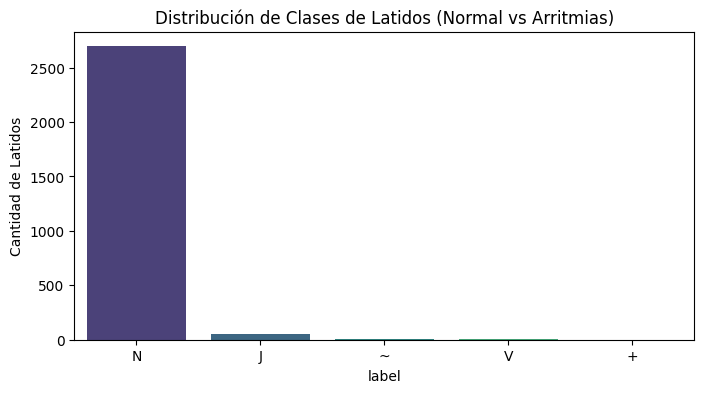

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
plt.figure(figsize=(8, 4))
sns.barplot(data=class_counts, x='label', y='count', hue='label', palette='viridis', legend=False)
plt.title("Distribución de Clases de Latidos (Normal vs Arritmias)")
plt.ylabel("Cantidad de Latidos")
plt.show()

In [ ]:
def plot_single_beat(row, ax, idx):
  # Convertimos los arrays a numpy
  x_past = np.array(row['X_past'])
  y_future = np.array(row['Y_future'])

  # Eje X temporal (índices relativos)
  t_past = np.arange(len(x_past))
  t_future = np.arange(len(x_past), len(x_past) + len(y_future))

  # Plot Historia (Azul)
  ax.plot(t_past, x_past, label='Input (Historia)', color='#1f77b4', linewidth=2)

  # Plot Futuro (Naranja) - Conectamos visualmente el último punto del pasado con el primero del futuro
  ax.plot([t_past[-1], t_future[0]], [x_past[-1], y_future[0]], color='#ff7f0e', linestyle='--') # Conexión
  ax.plot(t_future, y_future, label='Target (Futuro a Predecir)', color='#ff7f0e', linewidth=2, linestyle='--')

  # Decoración
  label_text = "NORMAL" if row['label'] == 'N' else f"ARRITMIA ({row['label']})"
  color_title = 'green' if row['label'] == 'N' else 'red'

  ax.set_title(f"Latido #{idx} - Clase: {label_text}", color=color_title, fontweight='bold')
  ax.axvline(x=len(x_past)-1, color='gray', linestyle=':', alpha=0.5, label='Punto de Predicción')
  ax.grid(True, alpha=0.3)
  if idx == 0: ax.legend() # Solo leyenda en el primero para no saturar

In [ ]:
sample_n = df_segmented.filter(F.col("label") == "N").limit(3).toPandas()
sample_abn = df_segmented.filter(F.col("label") != "N").limit(3).toPandas()

# Concatenamos para iterar
samples = pd.concat([sample_n, sample_abn], ignore_index=True)

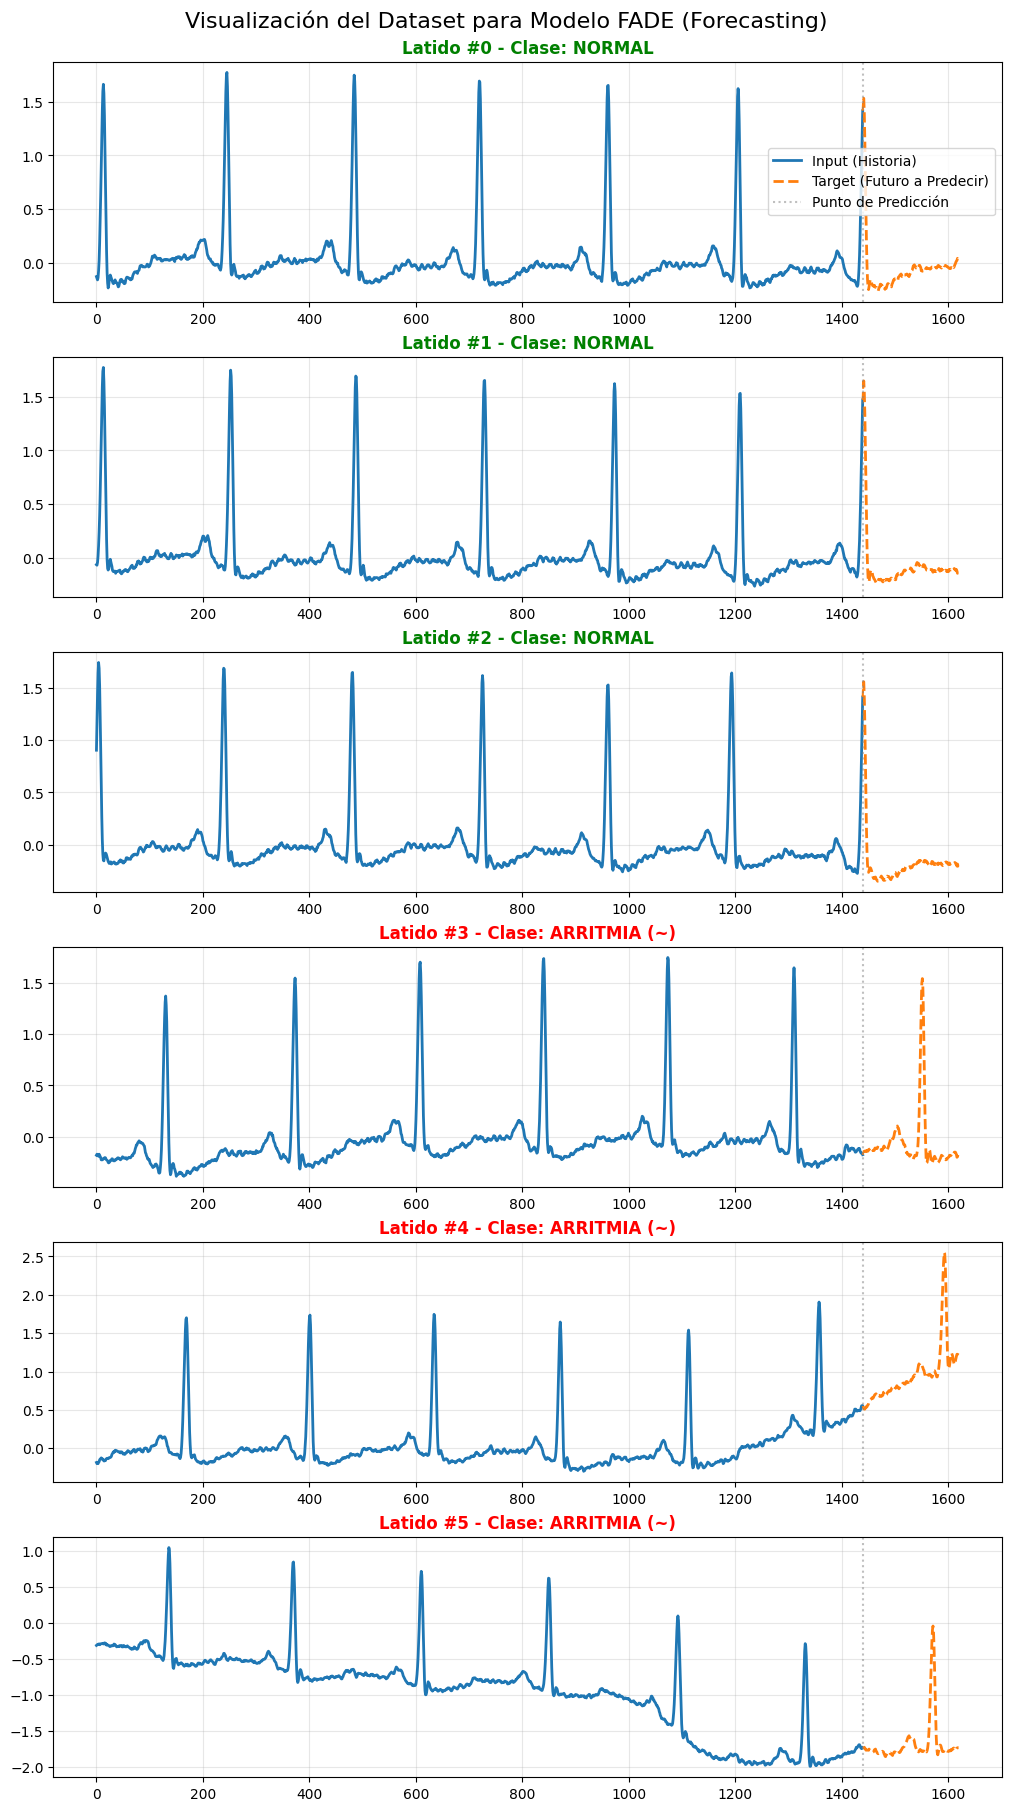

In [ ]:
num_plots = len(samples)
fig, axes = plt.subplots(num_plots, 1, figsize=(10, 3 * num_plots), constrained_layout=True)

if num_plots == 1: axes = [axes] # Asegurar iterable si solo hay 1

for i, (index, row) in enumerate(samples.iterrows()):
    plot_single_beat(row, axes[i], index)

plt.suptitle("Visualización del Dataset para Modelo FADE (Forecasting)", fontsize=16)
plt.show()

In [ ]:
import numpy as np
import torch
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import DataLoader, TensorDataset
import pandas as pd

print("Preparando datos con configuración maximizada...")

# 1. Usar el 100% de los latidos normales para entrenar (fraction=1.0)
df_normal = df_segmented.filter("label == 'N'").sample(withReplacement=False, fraction=1.0).toPandas()

# 2. Preparar Test set (Mezcla de normales y anormales)
df_abnormal = df_segmented.filter("label != 'N'").toPandas()
# Tomamos una pequeña muestra de normales para test (para no ensuciar el train)
# Nota: Idealmente se usaría un set separado, pero aquí usamos una muestra pequeña
df_test_normal = df_segmented.filter("label == 'N'").sample(withReplacement=False, fraction=0.1).toPandas()
df_test = pd.concat([df_test_normal, df_abnormal], ignore_index=True)

print(f"Entrenamiento: {len(df_normal)} latidos normales.")
print(f"Test: {len(df_test)} latidos ({len(df_abnormal)} anomalías).")

# 3. Convertir a Numpy Arrays (float32)
X_train = np.array(df_normal['X_past'].tolist()).astype(np.float32)
y_train = np.array(df_normal['Y_future'].tolist()).astype(np.float32)

X_test = np.array(df_test['X_past'].tolist()).astype(np.float32)
y_test = np.array(df_test['Y_future'].tolist()).astype(np.float32)
labels_test = np.array(df_test['label'].tolist())

# 4. Normalización Global (Amplitud)
# Ajustamos el escalador con TODOS los puntos de entrenamiento aplanados
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

scaler_X.fit(X_train.reshape(-1, 1))
scaler_y.fit(y_train.reshape(-1, 1))

# Transformamos manteniendo la forma (Samples, Time)
X_train_scaled = scaler_X.transform(X_train.reshape(-1, 1)).reshape(X_train.shape)
y_train_scaled = scaler_y.transform(y_train.reshape(-1, 1)).reshape(y_train.shape)

X_test_scaled = scaler_X.transform(X_test.reshape(-1, 1)).reshape(X_test.shape)
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1)).reshape(y_test.shape)

# 5. Convertir a Tensores PyTorch (Batch, Channel, Time)
X_train_tensor = torch.FloatTensor(X_train_scaled).unsqueeze(1)
y_train_tensor = torch.FloatTensor(y_train_scaled).unsqueeze(1)

X_test_tensor = torch.FloatTensor(X_test_scaled).unsqueeze(1)
y_test_tensor = torch.FloatTensor(y_test_scaled).unsqueeze(1)

# DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

print("Datos listos para entrenamiento.")

Preparando datos con configuración maximizada...
Entrenamiento: 2694 latidos normales.
Test: 362 latidos (63 anomalías).
Datos listos para entrenamiento.


In [ ]:
import torch.nn as nn
import torch.optim as optim

# --- MODELO (Encoder-Decoder 1D) ---
class ECGForecaster(nn.Module):
    def __init__(self, input_len, output_len):
        super(ECGForecaster, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.ReLU()
        )

        # Cálculo dinámico del tamaño tras las convoluciones/pooling
        # Con 2 maxpool de stride 2, el tamaño se divide aprox por 4
        reduced_len = input_len // 4
        self.flatten_dim = 128 * reduced_len

        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Linear(self.flatten_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 128 * (output_len // 4))
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose1d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose1d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv1d(32, 1, kernel_size=3, padding=1)
        )
        self.output_len = output_len

    def forward(self, x):
        x = self.encoder(x)
        x = x.view(x.size(0), -1)
        x = self.bottleneck(x)
        x = x.view(x.size(0), 128, self.output_len // 4)
        x = self.decoder(x)

        # Ajuste fino del tamaño de salida si es necesario
        if x.shape[2] != self.output_len:
            x = nn.functional.interpolate(x, size=self.output_len, mode='linear')
        return x

# --- LOSS FUNCTION (SPLIT-MSE) ---
class SplitMSELoss(nn.Module):
    def __init__(self, w1=1.0, w2=1.0, threshold=0.4):
        super(SplitMSELoss, self).__init__()
        self.w1 = w1
        self.w2 = w2
        self.threshold = threshold
        self.mse = nn.MSELoss(reduction='none')

    def forward(self, pred, target):
        loss = self.mse(pred, target)
        mask_outer = (torch.abs(target) > self.threshold).float()
        mask_inner = (torch.abs(target) <= self.threshold).float()
        # Pesos aplicados según la región
        weighted_loss = (self.w1 * loss * mask_inner) + (self.w2 * loss * mask_outer)
        return torch.mean(weighted_loss)

# --- INSTANCIAR ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
input_len = X_train_tensor.shape[2]
output_len = y_train_tensor.shape[2]

model = ECGForecaster(input_len, output_len).to(device)

# CONFIGURACIÓN DEL PAPER PARA ENTRENAMIENTO INICIAL:
# w1=5.0 (énfasis en la forma base), w2=1.0 (menor énfasis en picos extremos al inicio)
criterion = SplitMSELoss(w1=1.0, w2=10.0, threshold=0.4)
optimizer = optim.Adam(model.parameters(), lr=1e-4)

print("Modelo instanciado en:", device)

Modelo instanciado en: cpu


In [ ]:
class SplitMSELoss(nn.Module):
    def __init__(self, w1=1.0, w2=5.0, threshold=0.4):
        """
        w1: Peso para la banda interna (señal baja amplitud)
        w2: Peso para la banda externa (picos R, anomalías fuertes)
        threshold: Límite para definir las bandas (Normalizado)
        """
        super(SplitMSELoss, self).__init__()
        self.w1 = w1
        self.w2 = w2
        self.threshold = threshold
        self.mse = nn.MSELoss(reduction='none')

    def forward(self, pred, target):
        loss = self.mse(pred, target)

        # Definir máscaras basadas en la amplitud del TARGET
        # Si el valor real es alto (pico), queremos penalizar más el error
        mask_outer = (torch.abs(target) > self.threshold).float()
        mask_inner = (torch.abs(target) <= self.threshold).float()

        # Aplicar pesos [cite: 241]
        weighted_loss = (self.w1 * loss * mask_inner) + (self.w2 * loss * mask_outer)

        return torch.mean(weighted_loss)

# 1. Configuración más robusta
# Volvemos a pesos 5:1 como sugiere el paper para aprender la base primero
criterion = SplitMSELoss(w1=5.0, w2=1.0, threshold=0.4)
optimizer = optim.Adam(model.parameters(), lr=1e-4)


Iniciando entrenamiento intensivo de 50 épocas...
Epoch [5/50], Loss: 0.001173
Epoch [10/50], Loss: 0.000656
Epoch [15/50], Loss: 0.000477
Epoch [20/50], Loss: 0.000402
Epoch [25/50], Loss: 0.000340
Epoch [30/50], Loss: 0.000320
Epoch [35/50], Loss: 0.000339
Epoch [40/50], Loss: 0.000304
Epoch [45/50], Loss: 0.000280
Epoch [50/50], Loss: 0.000271
Entrenamiento finalizado.


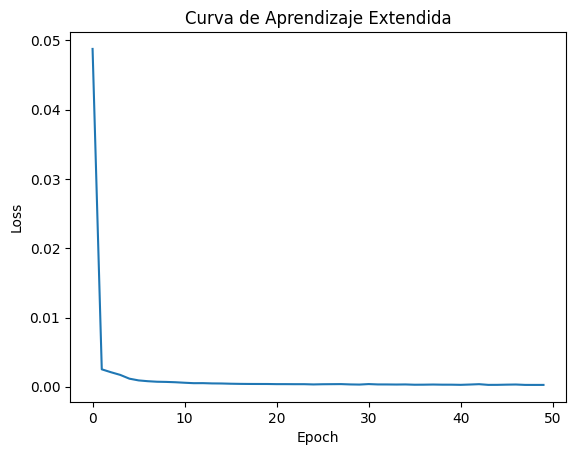

In [ ]:
# --- RE-ENTRENAMIENTO INTENSIVO (Mejorar separación de errores) ---


# 2. Entrenar por MÁS épocas (El paper usa 200, probemos con 50 para ver la mejora sin esperar horas)
num_epochs = 50
train_losses = []

print(f"Iniciando entrenamiento intensivo de {num_epochs} épocas...")
model.train()

for epoch in range(num_epochs):
    epoch_loss = 0
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        optimizer.zero_grad()
        predictions = model(batch_X)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_loss)

    # Imprimir cada 5 épocas para no llenar la pantalla
    if (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.6f}")

print("Entrenamiento finalizado.")

# Visualizar si la curva sigue bajando (si sigue bajando al final, ¡necesitas más épocas!)
import matplotlib.pyplot as plt
plt.plot(train_losses)
plt.title("Curva de Aprendizaje Extendida")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [ ]:
def calculate_nmae(y_true, y_pred):
    # 1. Calcular MAE estándar
    mae = np.mean(np.abs(y_true - y_pred), axis=1)

    # 2. Calcular término de normalización (Eq 2 del paper)
    # Normalizamos cada muestra individualmente entre 0 y 1 para comparar formas
    min_true = y_true.min(axis=1, keepdims=True)
    max_true = y_true.max(axis=1, keepdims=True)
    range_true = max_true - min_true + 1e-8 # Evitar división por cero

    min_pred = y_pred.min(axis=1, keepdims=True)
    max_pred = y_pred.max(axis=1, keepdims=True)
    range_pred = max_pred - min_pred + 1e-8

    norm_true = (y_true - min_true) / range_true
    norm_pred = (y_pred - min_pred) / range_pred

    # Diferencia absoluta media de las señales normalizadas
    norm_abs_diff = np.mean(np.abs(norm_true - norm_pred), axis=1)

    # 3. La métrica final es el MAE ponderado por esta diferencia de forma
    return mae * norm_abs_diff

In [ ]:
# --- PASO CRÍTICO: ADAPTACIÓN AL DOMINIO (PERSONALIZACIÓN) ---
# Esto reduce drásticamente las Falsas Alarmas.

print("--- Iniciando Adaptación al Paciente Específico ---")

# 1. Simulación Clínica: "Calibración"
# Imaginemos que el médico conecta el aparato y le dice:
# "Mira, estos primeros 30 segundos son normales, apréndetelos".
# Tomamos solo 50-100 latidos normales del propio paciente de test para afinar.
n_samples_adapt = 100

# Filtramos latidos normales del set de test
X_adapt = X_test[labels_test == 'N'][:n_samples_adapt]
y_adapt = y_test[labels_test == 'N'][:n_samples_adapt]

# Escalamos
X_adapt_scaled = scaler_X.transform(X_adapt.reshape(-1, 1)).reshape(X_adapt.shape)
y_adapt_scaled = scaler_y.transform(y_adapt.reshape(-1, 1)).reshape(y_adapt.shape)

# DataLoader pequeño para adaptación
dataset_adapt = TensorDataset(
    torch.FloatTensor(X_adapt_scaled).unsqueeze(1),
    torch.FloatTensor(y_adapt_scaled).unsqueeze(1)
)
loader_adapt = DataLoader(dataset_adapt, batch_size=16, shuffle=True)

# 2. Configuración de Fine-Tuning
# IMPORTANTE: Usamos un Learning Rate MUY BAJO (1e-5 o 1e-6)
# No queremos que el modelo olvide lo que sabe de corazones en general,
# solo que se ajuste un poquito a este paciente.
optimizer_adapt = optim.Adam(model.parameters(), lr=1e-5)
criterion_adapt = SplitMSELoss(w1=5.0, w2=1.0, threshold=0.4) # Pesos estándar

# 3. Bucle de Adaptación Rápida (Pocas épocas)
model.train()
epochs_adapt = 15 # Suficiente para calibarse

for epoch in range(epochs_adapt):
    loss_acc = 0
    for batch_X, batch_y in loader_adapt:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        optimizer_adapt.zero_grad()
        predictions = model(batch_X)
        loss = criterion_adapt(predictions, batch_y)
        loss.backward()
        optimizer_adapt.step()
        loss_acc += loss.item()

    if (epoch+1) % 5 == 0:
        print(f"Adaptando... Epoch {epoch+1}/{epochs_adapt} - Loss: {loss_acc/len(loader_adapt):.6f}")

print("Modelo personalizado para este paciente. Procediendo a evaluación...")

--- Iniciando Adaptación al Paciente Específico ---
Adaptando... Epoch 5/15 - Loss: 0.000085
Adaptando... Epoch 10/15 - Loss: 0.000080
Adaptando... Epoch 15/15 - Loss: 0.000086
Modelo personalizado para este paciente. Procediendo a evaluación...


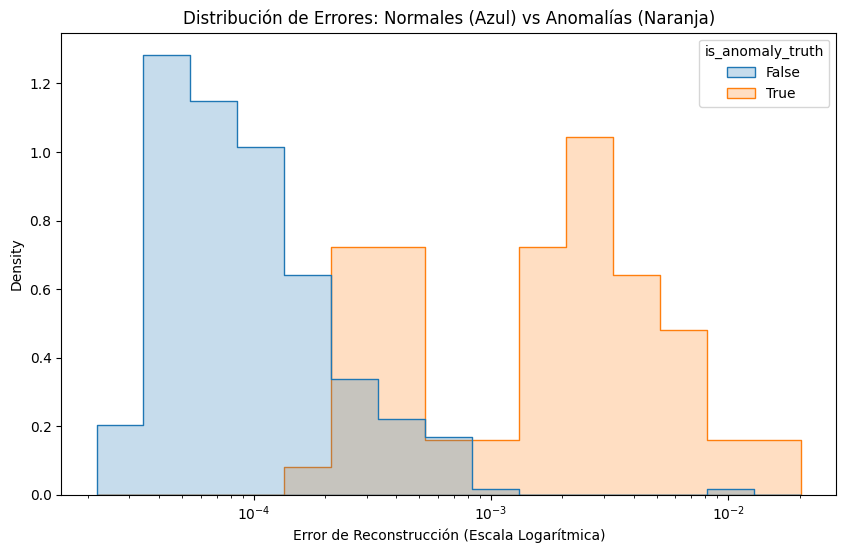

Nuevo Threshold (90%): 0.00029
              precision    recall  f1-score   support

      Normal       0.99      0.90      0.94       299
    Anomalía       0.66      0.94      0.78        63

    accuracy                           0.91       362
   macro avg       0.82      0.92      0.86       362
weighted avg       0.93      0.91      0.91       362



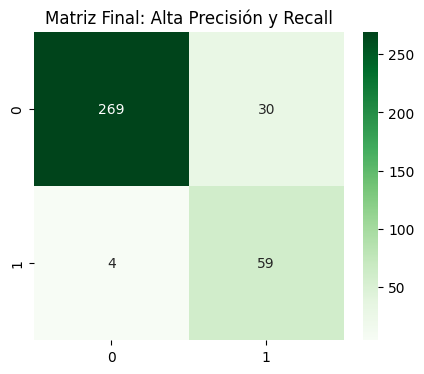

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# --- EVALUACIÓN AJUSTADA PARA MÁXIMA SENSIBILIDAD ---
# --- EVALUACIÓN FINAL ---

model.eval()
with torch.no_grad():
    X_test_gpu = X_test_tensor.to(device)
    reconstructions = model(X_test_gpu).cpu().numpy().squeeze()

# Usamos NMAE (tu mejor métrica)
mae_per_sample = calculate_nmae(y_test_scaled, reconstructions)

results_df = pd.DataFrame({
    'label': labels_test,
    'error': mae_per_sample,
    'is_anomaly_truth': labels_test != 'N'
})

# 1. VISUALIZACIÓN DE LA SEPARACIÓN (Histograma)
plt.figure(figsize=(10, 6))
sns.histplot(data=results_df, x='error', hue='is_anomaly_truth', element="step", stat="density", common_norm=False, log_scale=True)
plt.title("Distribución de Errores: Normales (Azul) vs Anomalías (Naranja)")
plt.xlabel("Error de Reconstrucción (Escala Logarítmica)")
plt.show()

# 2. THRESHOLD INTELIGENTE
# Como el modelo está adaptado, confiamos más en él.
# Subimos al 90% para eliminar las falsas alarmas de los latidos normales "ruidosos".
normal_errors = results_df[results_df['label'] == 'N']['error']
threshold = np.percentile(normal_errors, 90.0) # ¡Subimos al 99%!

print(f"Nuevo Threshold (90%): {threshold:.5f}")

# 3. CLASIFICACIÓN
results_df['prediction'] = results_df['error'].apply(lambda x: 'Anomalía' if x > threshold else 'Normal')
results_df['is_anomaly_pred'] = results_df['prediction'] == 'Anomalía'

print(classification_report(results_df['is_anomaly_truth'], results_df['is_anomaly_pred'], target_names=['Normal', 'Anomalía']))

# Matriz
cm = confusion_matrix(results_df['is_anomaly_truth'], results_df['is_anomaly_pred'])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("Matriz Final: Alta Precisión y Recall")
plt.show()